In [71]:
from pathlib import Path
import pandas as pd
from credit_card_fraud_detection.paths import ROOT, INTERIM
from datetime import date
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
train = INTERIM / "train_interim.csv"
test = INTERIM / "test_interim.csv"

In [4]:
train_df = pd.read_csv(train)
test_df = pd.read_csv(test)

"High-dollar transactions are where most of our fraud losses occur."

Variables-to-use
* amount_usd
* is_fraud_
* velocity
* merchant_category

In [78]:
q1_cols = ["amount_usd", "is_fraud", "velocity_score", "merchant_category"]
q1_df = train_df[q1_cols]
q1_df.head()

,amount_usd,is_fraud,velocity_score,merchant_category
0,61.16,0.0,5.5,Groceries
1,24.83,0.0,33.4,Online Retail
2,6.36,0.0,35.8,Utilities
3,37.44,0.0,20.7,Groceries
4,653.85,0.0,34.8,Electronics


In [79]:
# group transaction into amount brackets using amount_usd
bins = [0, 50, 200, 1000, float("inf")]
labels = ["$0 - $50", "$50 - $200", "$200 - $1,000", "$1,000+"]
q1_df = (
    q1_df.groupby(pd.cut(q1_df["amount_usd"], bins=bins, labels=labels))["is_fraud"]
    .agg(["sum", "mean"])
    .rename(columns={"sum": "total_fraud", "mean": "fraud_pct"})
    .assign(fraud_pct=lambda x: x["fraud_pct"]*100)
    .reset_index()
)

In [80]:
q1_df.sort_values(by="total_fraud", ascending=False).head()

,amount_usd,total_fraud,fraud_pct
0,$0 - $50,8790.0,1.520183
1,$50 - $200,1466.0,2.179926
2,"$200 - $1,000",1297.0,2.644834
3,"$1,000+",136.0,2.494955


<BarContainer object of 4 artists>

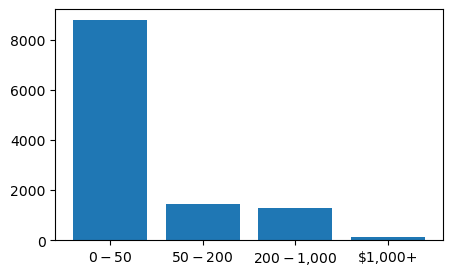

In [81]:
# barplot  to see the difference
fig, ax = plt.subplots(figsize=(5, 3))
ax.bar(q1_df["amount_usd"], q1_df["total_fraud"])

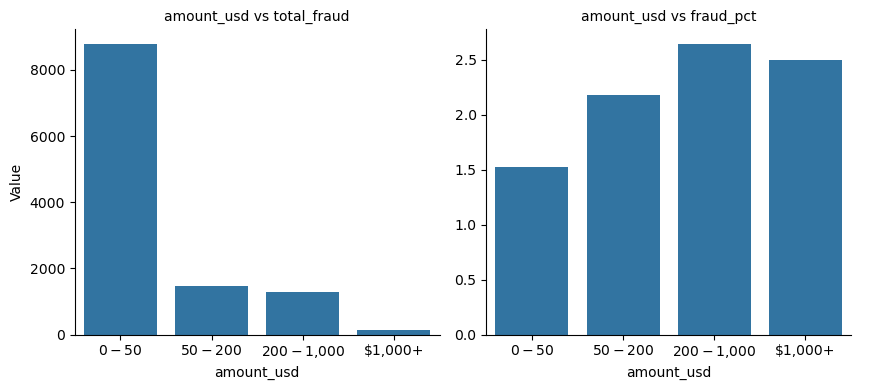

In [90]:
# catplot for multiple bar
# first melt it since we have both required y columns as seperate columns, catplot requires in total 2 columns only X and Y
# melt achieves this
q1_df_long = q1_df.melt(
    id_vars="amount_usd", #to keep fixed or X-axis
    value_vars = ["total_fraud", "fraud_pct"],
    var_name="Group",
    value_name="Value"
)

g = sns.catplot(
    data=q1_df_long,
    x="amount_usd",
    y="Value",
    col="Group",
    kind="bar",
    sharey= False, # make each y-axis have seperate scale and not share amongst each other
    height=4,
    aspect=1.1,
)

g.set_titles("amount_usd vs {col_name}")
g.tight_layout()
plt.show()

<h4>most of the loss is from high frequency low value fraud</h4>

"5+ year accounts are riskier than younger accounts."

Variables-to-use
* card_age_months
* is_fraud

In [114]:
q2_cols = ["card_age_months", "is_fraud"]
q2_df = train_df[q2_cols]
q2_df.head()

,card_age_months,is_fraud
0,48,0.0
1,38,0.0
2,50,0.0
3,48,0.0
4,37,0.0


In [ ]:
# group transaction into month brackets using card_age_months
bins = [24, 36, 48, 60, float("inf")]
labels = ["2-3 years", "3-4 years", "4-5 years", "5 years+"]
q2_df = (
    q2_df.groupby(pd.cut(q2_df["card_age_months"], bins=bins, labels=labels))["is_fraud"]
    .agg(["mean"])
    .rename(columns={"mean": "fraud_pct"})
    .assign(fraud_pct=lambda x: x["fraud_pct"]*100)
    .reset_index()
)

<Axes: xlabel='card_age_months', ylabel='fraud_pct'>

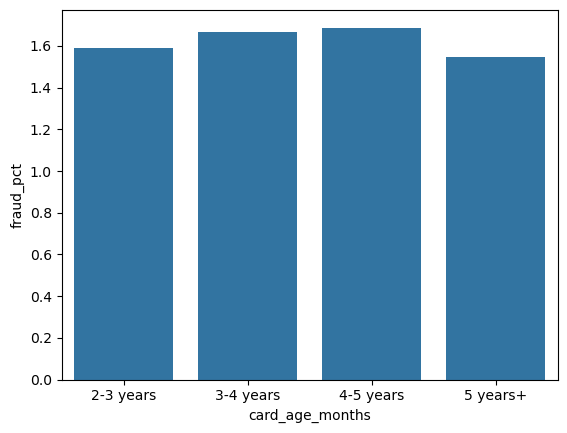

In [ ]:
sns.barplot(data=q2_df, x="card_age_months", y="fraud_pct", errorbar=None)

<h4>There seems to be no significant difference between fraud rate with 5+ year old card account versus < 5 year old account </h4>

"International and out-of-state transactions are almost always fraudulent."

Variables-to-use
* is_foreign_transaction
* ip_country_mismatch
* distance_from_home_km
* is_fraud

In [133]:
q3_cols = ["is_foreign_transaction", "ip_country_mismatch", "distance_from_home_km", "is_fraud"]
q3_df = train_df[q3_cols]
q3_df.head()

,is_foreign_transaction,ip_country_mismatch,distance_from_home_km,is_fraud
0,False,False,17.78,0.0
1,False,False,13.06,0.0
2,False,False,8.17,0.0
3,False,False,8.67,0.0
4,False,False,11.69,0.0


In [134]:
# before crosstabl, we will bin distance_from_home_km
bin = [0, 10, 20, 30, 40, 1000]
labels = ['Very near (<10km)', 'close by (10-20km)', 'not that far (20-30km)', 'far (30-40km)', ' very far (40+km)']
q3_df['distance_bins'] = pd.cut(q3_df['distance_from_home_km'], bins=bin, labels=labels, right=False)
q3_df.head()

,is_foreign_transaction,ip_country_mismatch,distance_from_home_km,is_fraud,distance_bins
0,False,False,17.78,0.0,close by (10-20km)
1,False,False,13.06,0.0,close by (10-20km)
2,False,False,8.17,0.0,Very near (<10km)
3,False,False,8.67,0.0,Very near (<10km)
4,False,False,11.69,0.0,close by (10-20km)


In [135]:
#cross tab
rates_ct = pd.crosstab(
    index=[q3_df['is_foreign_transaction'], q3_df['ip_country_mismatch'], q3_df['distance_bins']],
    columns=q3_df['is_fraud'],
    normalize='index'
)

#rename columns
rates_ct = rates_ct.rename(columns={0: 'False_Alarm_Rate', 1: 'Precision_Fraud_Rate'})

#format as percentage
display((rates_ct*100).round(2))

is_fraud                                                           False_Alarm_Rate  \
is_foreign_transaction ip_country_mismatch distance_bins                              
False                  False               Very near (<10km)                  98.66   
                                           close by (10-20km)                 98.65   
                                           not that far (20-30km)             98.63   
                                           far (30-40km)                      98.59   
                                            very far (40+km)                  98.62   
                       True                Very near (<10km)                  88.11   
                                           close by (10-20km)                 88.13   
                                           not that far (20-30km)             86.58   
                                           far (30-40km)                      87.61   
                                            very far (40+km)                  85.38   
True                   False               Very near (<10km)                  92.88   
                                           close by (10-20km)                 92.73   
                                           not that far (20-30km)             93.09   
                                           far (30-40km)                      92.94   
                                            very far (40+km)                  93.84   
                       True                Very near (<10km)                  72.95   
                                           close by (10-20km)                 76.58   
                                           not that far (20-30km)             72.10   
                                           far (30-40km)                      75.77   
                                            very far (40+km)                  75.74   

is_fraud                                                           Precision_Fraud_Rate  
is_foreign_transaction ip_country_mismatch distance_bins                                 
False                  False               Very near (<10km)                       1.34  
                                           close by (10-20km)                      1.35  
                                           not that far (20-30km)                  1.37  
                                           far (30-40km)                           1.41  
                                            very far (40+km)                       1.38  
                       True                Very near (<10km)                      11.89  
                                           close by (10-20km)                     11.87  
                                           not that far (20-30km)                 13.42  
                                           far (30-40km)                          12.39  
                                            very far (40+km)                      14.62  
True                   False               Very near (<10km)                       7.12  
                                           close by (10-20km)                      7.27  
                                           not that far (20-30km)                  6.91  
                                           far (30-40km)                           7.06  
                                            very far (40+km)                       6.16  
                       True                Very near (<10km)                      27.05  
                                           close by (10-20km)                     23.42  
                                           not that far (20-30km)                 27.90  
                                           far (30-40km)                          24.23  
                                            very far (40+km)                      24.26

In [138]:
counts_ct = pd.crosstab(
    index=[q3_df['is_foreign_transaction'], q3_df['ip_country_mismatch'], q3_df['distance_bins']],
    columns=q3_df['is_fraud'],
    margins=True,
    margins_name='Total_Transactions'
)

display(counts_ct)

is_fraud                                                              0.0  \
is_foreign_transaction ip_country_mismatch distance_bins                    
False                  False               Very near (<10km)       328879   
                                           close by (10-20km)      175936   
                                           not that far (20-30km)   90994   
                                           far (30-40km)            49172   
                                            very far (40+km)        25884   
                       True                Very near (<10km)         3342   
                                           close by (10-20km)        1804   
                                           not that far (20-30km)     910   
                                           far (30-40km)              516   
                                            very far (40+km)          257   
True                   False               Very near (<10km)         3900   
                                           close by (10-20km)        2041   
                                           not that far (20-30km)    1092   
                                           far (30-40km)              592   
                                            very far (40+km)          335   
                       True                Very near (<10km)         1281   
                                           close by (10-20km)         713   
                                           not that far (20-30km)     323   
                                           far (30-40km)              197   
                                            very far (40+km)          103   
Total_Transactions                                                 688271   

is_fraud                                                             1.0  \
is_foreign_transaction ip_country_mismatch distance_bins                   
False                  False               Very near (<10km)        4479   
                                           close by (10-20km)       2406   
                                           not that far (20-30km)   1267   
                                           far (30-40km)             701   
                                            very far (40+km)         363   
                       True                Very near (<10km)         451   
                                           close by (10-20km)        243   
                                           not that far (20-30km)    141   
                                           far (30-40km)              73   
                                            very far (40+km)          44   
True                   False               Very near (<10km)         299   
                                           close by (10-20km)        160   
                                           not that far (20-30km)     81   
                                           far (30-40km)              45   
                                            very far (40+km)          22   
                       True                Very near (<10km)         475   
                                           close by (10-20km)        218   
                                           not that far (20-30km)    125   
                                           far (30-40km)              63   
                                            very far (40+km)          33   
Total_Transactions                                                 11689   

is_fraud                                                           Total_Transactions  
is_foreign_transaction ip_country_mismatch distance_bins                               
False                  False               Very near (<10km)                   333358  
                                           close by (10-20km)                  178342  
                                           not that far (20-30km)               92261  
                                       